<h1 align='center'>🎓 Projet de Fin de Module — Deep Learning</h1>
<h3 align='center'>EMSI Casablanca &nbsp;|&nbsp; Département Informatique &nbsp;|&nbsp; 2025–2026</h3>

---

Ce notebook constitue le rapport intégral du projet de fin de module. Il recouvre trois grandes familles d'architectures étudiées au cours du semestre : **les MLP** pour les données structurées, **les CNN** pour la vision par ordinateur, et **les RNN/LSTM/GRU** pour la modélisation de séquences. Pour chaque partie, on trouvera une présentation théorique, une mise en œuvre sous PyTorch, des expériences comparatives et une réflexion critique argumentée.

---
# ◆ PARTIE I — Perceptron Multi-couche et Ingénierie PyTorch

> **Problème traité :** Classer des tumeurs du sein (bénignes ou malignes) à partir de caractéristiques cellulaires tabulaires, en s'appuyant sur un MLP construit de deux façons distinctes sous PyTorch.

## ▸ A. Fondements théoriques de PyTorch

Avant d'écrire la moindre ligne de code, il est essentiel de comprendre les abstractions sur lesquelles repose PyTorch.

---

### 🔹 `nn.Module` — Le conteneur universel

Tout réseau de neurones en PyTorch hérite obligatoirement de `nn.Module`. Ce n'est pas une simple formalité : cette classe joue le rôle d'un **gestionnaire d'état** qui :

| Fonction | Description |
|---|---|
| Organisation | Regroupe les couches (Linear, Conv2d…) de façon hiérarchique |
| Suivi automatique | Enregistre tous les tenseurs marqués comme `nn.Parameter` |
| Bascule de mode | `.train()` active Dropout/BatchNorm ; `.eval()` les désactive |

**Contrat obligatoire :** toute sous-classe doit redéfinir la méthode `forward()`, qui décrit le flux de calcul lors d'un passage en avant.

### 🔹 Paramètres apprenables ($W$ et $b$)

Un réseau apprend en ajustant ses **paramètres** : les poids $W$ (qui pondèrent chaque entrée) et les biais $b$ (qui décalent les sorties). Sous PyTorch, ces quantités sont encapsulées dans `nn.Parameter`, un sous-type de `Tensor` automatiquement détecté par l'optimiseur lors de la mise à jour.

$$\text{sortie d'une couche} = W \cdot x + b$$

### 🔹 Gradient — Le signal de correction

La direction dans laquelle modifier les paramètres pour diminuer l'erreur est donnée par le **gradient** de la fonction de perte $\mathcal{L}$ :

$$\nabla_W \mathcal{L} = \frac{\partial \mathcal{L}}{\partial W}$$

PyTorch calcule ce vecteur automatiquement via son moteur **Autograd** en appelant `.backward()` sur la perte scalaire. Chaque tenseur a un graphe de calcul associé qui rend cette dérivation automatique possible.

### 🔹 `state_dict` — La mémoire photographique du modèle

Imaginez un dictionnaire dont les clés sont les noms des couches (`'hidden1.weight'`, `'out.bias'`…) et les valeurs sont les tenseurs numériques correspondants. C'est exactement ce qu'est le `state_dict`. Il permet de :
- **Sauvegarder** un modèle entraîné sur disque avec `torch.save()`
- **Restaurer** ses poids dans une architecture identique avec `load_state_dict()`

### 🔹 Device — Où les calculs s'effectuent

PyTorch distingue deux espaces de calcul :
- **CPU** — par défaut, adapté aux petits modèles ou au débogage
- **GPU (CUDA)** — accélère massivement les multiplications matricielles grâce au parallélisme

⚠️ **Règle absolue :** modèle et données doivent résider sur le **même device**. Un mismatch provoque une erreur d'exécution immédiate. On utilise `.to(device)` pour déplacer n'importe quel objet.

### 🔹 Propagation avant & rétropropagation

**Passe avant :** les données $X$ traversent le réseau couche par couche, chacune appliquant une transformation affine puis une non-linéarité :

$$A^{(l)} = \sigma\bigl(W^{(l)} \cdot A^{(l-1)} + b^{(l)}\bigr)$$

À la fin, on compare la sortie $\hat{y}$ à la vérité $y$ pour calculer la perte $\mathcal{L}$.

**Passe arrière :** en remontant le réseau de la sortie vers l'entrée, la **règle de la chaîne** distribue les gradients à chaque paramètre. L'optimiseur met ensuite les poids à jour :

$$W \leftarrow W - \eta \cdot \nabla_W \mathcal{L}$$

où $\eta$ est le taux d'apprentissage. Cette boucle se répète pour chaque mini-lot jusqu'à convergence.

---
## ▸ B. Préparation du Dataset — Breast Cancer Wisconsin

**Contexte :** 699 observations de biopsies cellulaires, décrites par 9 caractéristiques cliniques (épaisseur des amas, uniformité des cellules…). La variable cible encode deux classes : bénin (2→0) et malin (4→1).

### Étape 1 — Chargement brut

In [1]:
import pandas as pd
import numpy as np
import urllib.request
import os

# ── Téléchargement automatique depuis UCI ──────────────────────────────────
URL       = "https://archive.ics.uci.edu/ml/machine-learning-databases/breast-cancer-wisconsin/breast-cancer-wisconsin.data"
file_path = "breast-cancer-wisconsin.data"

if not os.path.exists(file_path):
    print("Téléchargement du dataset depuis UCI...")
    urllib.request.urlretrieve(URL, file_path)
    print(f"✔ Fichier téléchargé → {file_path}")
else:
    print(f"✔ Fichier déjà présent → {file_path}")

col_names = [
    'id', 'clump_thickness', 'unif_cell_size', 'unif_cell_shape',
    'marg_adhesion', 'single_epith_size', 'bare_nuclei',
    'bland_chromatin', 'normal_nucleoli', 'mitoses', 'class'
]
df = pd.read_csv(file_path, names=col_names)
print(f"Dimensions brutes : {df.shape} | Colonnes : {list(df.columns)}")
df.head(3)


✔ Fichier déjà présent → breast-cancer-wisconsin.data
Dimensions brutes : (699, 11) | Colonnes : ['id', 'clump_thickness', 'unif_cell_size', 'unif_cell_shape', 'marg_adhesion', 'single_epith_size', 'bare_nuclei', 'bland_chromatin', 'normal_nucleoli', 'mitoses', 'class']


,id,clump_thickness,unif_cell_size,unif_cell_shape,marg_adhesion,single_epith_size,bare_nuclei,bland_chromatin,normal_nucleoli,mitoses,class
0,1000025,5,1,1,1,2,1,3,1,1,2
1,1002945,5,4,4,5,7,10,3,2,1,2
2,1015425,3,1,1,1,2,2,3,1,1,2


### Étape 2 — Nettoyage

Le fichier source encode les valeurs manquantes par le symbole `'?'` (16 occurrences dans `bare_nuclei`). On les convertit en `NaN` puis on élimine les lignes incomplètes — une approche acceptable ici car les données manquantes ne représentent que 2,3 % du total.

In [2]:
df = df.replace('?', np.nan).dropna()            # NaN → suppression
df['bare_nuclei'] = df['bare_nuclei'].astype(int) # reconversion numérique
df = df.drop('id', axis=1)                        # identifiant non informatif

print(f"Après nettoyage : {df.shape} | NaN restants : {df.isnull().sum().sum()}")
print(f"Distribution des classes :\n{df['class'].value_counts()}")

Après nettoyage : (683, 10) | NaN restants : 0
Distribution des classes :
class
2    444
4    239
Name: count, dtype: int64


### Étape 3 — Normalisation et conversion en Tenseurs

**Pourquoi normaliser ?** Les neurones sont entraînés par descente de gradient. Si les features ont des échelles très différentes, les gradients associés aux grandes valeurs dominent et ralentissent ou déstabilisent la convergence. Le `StandardScaler` centre chaque colonne à zéro et la réduit à un écart-type unitaire.

> ⚠️ Le scaler est **ajusté uniquement sur le train set**, puis appliqué tel quel au test set. Ajuster sur le test introduirait une fuite d'information (*data leakage*).

In [3]:
import torch
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X = df.drop('class', axis=1).values
y = df['class'].map({2: 0, 4: 1}).values          # encodage binaire

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

scaler  = StandardScaler()
X_train = scaler.fit_transform(X_train)  # fit + transform sur train
X_test  = scaler.transform(X_test)       # transform seul sur test

# Conversion vers PyTorch
X_tr = torch.tensor(X_train, dtype=torch.float32)
y_tr = torch.tensor(y_train, dtype=torch.float32).unsqueeze(1)
X_te = torch.tensor(X_test,  dtype=torch.float32)
y_te = torch.tensor(y_test,  dtype=torch.float32).unsqueeze(1)

print(f"Train : {X_tr.shape}  |  Test : {X_te.shape}")

Train : torch.Size([546, 9])  |  Test : torch.Size([137, 9])


---
## ▸ C. Construction du MLP — Deux Approches PyTorch

PyTorch offre deux manières d'assembler un réseau. Les deux produisent des modèles fonctionnellement équivalents, mais leurs cas d'usage diffèrent.

### 🅐 Approche déclarative avec `nn.Sequential`

Idéale pour les architectures linéaires simples. Les couches sont empilées dans un conteneur ordonné ; le `forward()` est implicite.

In [4]:
from torch import nn

mlp_seq = nn.Sequential(
    nn.LazyLinear(16),  # couche cachée 1  :  9 → 16 neurones
    nn.ReLU(),
    nn.LazyLinear(8),   # couche cachée 2  : 16 →  8 neurones
    nn.ReLU(),
    nn.LazyLinear(1)    # sortie binaire   :  8 →  1 logit
)

# Un passage avant suffit à initialiser les dimensions (LazyLinear)
_ = mlp_seq(X_tr)
print("[Sequential] Sortie shape :", mlp_seq(X_tr).shape)

[Sequential] Sortie shape : torch.Size([546, 1])


### 🅑 Approche orientée objet avec une classe `nn.Module`

Préférable dès que l'on a besoin de : branches parallèles, connexions résiduelles, sorties intermédiaires, ou de toute logique conditionnelle dans `forward()`.

In [5]:
from torch.nn import functional as F

class BreastCancerNet(nn.Module):
    """
    MLP personnalisé pour la détection de tumeurs malignes.
    Architecture : 9 → 16 → 8 → 1  avec activations ReLU.
    """
    def __init__(self):
        super().__init__()
        self.fc1 = nn.LazyLinear(16)
        self.fc2 = nn.LazyLinear(8)
        self.fc3 = nn.LazyLinear(1)

    def forward(self, x):
        x = F.relu(self.fc1(x))  # activation non-linéaire ReLU : max(0, z)
        x = F.relu(self.fc2(x))
        return self.fc3(x)       # logit brut — sigmoid géré dans la fonction de perte

mlp_custom = BreastCancerNet()
_ = mlp_custom(X_tr)  # initialisation des dimensions
print("[Custom] Sortie shape :", mlp_custom(X_tr).shape)

[Custom] Sortie shape : torch.Size([546, 1])


---
## ▸ D. Inspection des Paramètres

### Via `named_parameters()` — cartographie structurelle

In [6]:
print("┌─ Modèle Sequential ─────────────────────────────────────────┐")
total = 0
for nom, p in mlp_seq.named_parameters():
    print(f"│  {nom:35s}  shape={str(p.shape):18s}  n={p.numel():5d}")
    total += p.numel()
print(f"└─ Total : {total} paramètres entraînables ─────────────────────┘")

┌─ Modèle Sequential ─────────────────────────────────────────┐
│  0.weight                             shape=torch.Size([16, 9])  n=  144
│  0.bias                               shape=torch.Size([16])    n=   16
│  2.weight                             shape=torch.Size([8, 16])  n=  128
│  2.bias                               shape=torch.Size([8])     n=    8
│  4.weight                             shape=torch.Size([1, 8])  n=    8
│  4.bias                               shape=torch.Size([1])     n=    1
└─ Total : 305 paramètres entraînables ─────────────────────┘


In [7]:
print("┌─ Modèle Classe Personnalisée ────────────────────────────────┐")
total = 0
for nom, p in mlp_custom.named_parameters():
    print(f"│  {nom:35s}  shape={str(p.shape):18s}  n={p.numel():5d}")
    total += p.numel()
print(f"└─ Total : {total} paramètres entraînables ─────────────────────┘")

┌─ Modèle Classe Personnalisée ────────────────────────────────┐
│  fc1.weight                           shape=torch.Size([16, 9])  n=  144
│  fc1.bias                             shape=torch.Size([16])    n=   16
│  fc2.weight                           shape=torch.Size([8, 16])  n=  128
│  fc2.bias                             shape=torch.Size([8])     n=    8
│  fc3.weight                           shape=torch.Size([1, 8])  n=    8
│  fc3.bias                             shape=torch.Size([1])     n=    1
└─ Total : 305 paramètres entraînables ─────────────────────┘


### Via `state_dict()` — inventaire des valeurs numériques

In [8]:
print("Clés du state_dict — Sequential  :", list(mlp_seq.state_dict().keys()))
print("Clés du state_dict — Custom      :", list(mlp_custom.state_dict().keys()))

Clés du state_dict — Sequential  : ['0.weight', '0.bias', '2.weight', '2.bias', '4.weight', '4.bias']
Clés du state_dict — Custom      : ['fc1.weight', 'fc1.bias', 'fc2.weight', 'fc2.bias', 'fc3.weight', 'fc3.bias']


---
## ▸ E. Trois Stratégies d'Initialisation

L'initialisation des poids conditionne la vitesse et la stabilité de l'apprentissage. Trois stratégies sont comparées ci-dessous.

| Stratégie | Formule | Usage conseillé |
|---|---|---|
| Gaussienne | $W \sim \mathcal{N}(0, 0.01^2)$ | Brise la symétrie — usage général |
| Constante | $W = c$ | Pédagogique seulement — à éviter |
| Xavier | $W \sim \mathcal{U}\!\left(-\!\sqrt{\tfrac{6}{n_{in}+n_{out}}}, +\!\sqrt{\tfrac{6}{n_{in}+n_{out}}}\right)$ | Sigmoid/Tanh — stabilise la variance |

In [9]:
# ── Gaussienne ──
def init_gaussienne(m):
    if isinstance(m, nn.Linear):
        nn.init.normal_(m.weight, mean=0, std=0.01)
        nn.init.zeros_(m.bias)

# ── Constante (problème de symétrie — usage pédagogique uniquement) ──
def init_constante(m):
    if isinstance(m, nn.Linear):
        nn.init.constant_(m.weight, 1.0)
        nn.init.zeros_(m.bias)

# ── Xavier / Glorot (recommandée pour Sigmoid & Tanh) ──
def init_xavier(m):
    if isinstance(m, nn.Linear):
        nn.init.xavier_uniform_(m.weight)
        nn.init.zeros_(m.bias)

# Application sur le modèle personnalisé
mlp_custom.apply(init_xavier)
print("Initialisation Xavier appliquée. Variance des poids fc1 :",
      round(mlp_custom.fc1.weight.var().item(), 6))

Initialisation Xavier appliquée. Variance des poids fc1 : 0.078059


Époque  10/50  |  Loss train=0.5891  Loss val=0.5349  Acc val=70.64 %
Époque  20/50  |  Loss train=0.5175  Loss val=0.4658  Acc val=73.39 %
Époque  30/50  |  Loss train=0.4529  Loss val=0.4016  Acc val=78.90 %
Époque  40/50  |  Loss train=0.3930  Loss val=0.3426  Acc val=88.07 %
Époque  50/50  |  Loss train=0.3366  Loss val=0.2872  Acc val=94.50 %


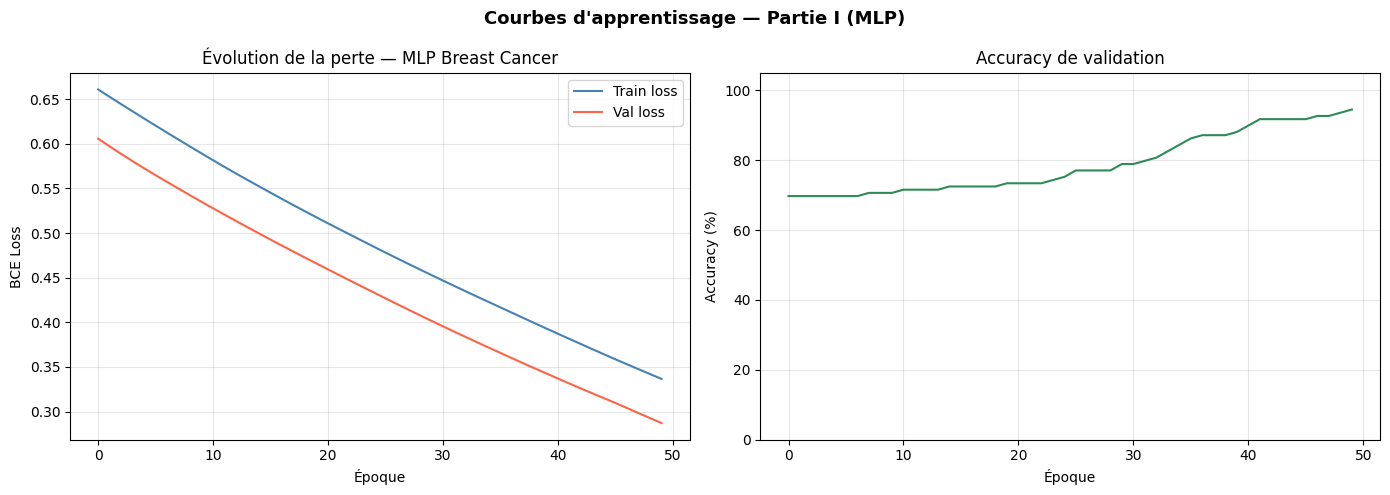


✔ Entraînement terminé. Meilleure acc val : 94.50 %


In [10]:
import torch
import torch.nn as nn
import torch.optim as optim

# ─────────────────────────────────────────────────────
# Boucle d'entraînement — Modèle personnalisé (Xavier)
# ─────────────────────────────────────────────────────
mlp_custom.apply(init_xavier)

criterion = nn.BCEWithLogitsLoss()          # stable : fusionne sigmoid + BCE
optimizer = optim.Adam(mlp_custom.parameters(), lr=1e-3)

N_EPOCHS   = 50
history    = {'train_loss': [], 'val_loss': [], 'val_acc': []}

# Split val depuis train (80/20 du train)
n_val  = int(0.2 * len(X_tr))
X_val, y_val   = X_tr[:n_val],  y_tr[:n_val]
X_t,   y_t     = X_tr[n_val:],  y_tr[n_val:]

for epoch in range(N_EPOCHS):
    mlp_custom.train()
    optimizer.zero_grad()
    logits_tr  = mlp_custom(X_t)
    loss_tr    = criterion(logits_tr, y_t)
    loss_tr.backward()
    optimizer.step()

    # Validation
    mlp_custom.eval()
    with torch.no_grad():
        logits_v   = mlp_custom(X_val)
        loss_v     = criterion(logits_v, y_val).item()
        preds_v    = (torch.sigmoid(logits_v) > 0.5).float()
        acc_v      = (preds_v == y_val).float().mean().item()

    history['train_loss'].append(loss_tr.item())
    history['val_loss'].append(loss_v)
    history['val_acc'].append(acc_v)

    if (epoch + 1) % 10 == 0:
        print(f"Époque {epoch+1:3d}/{N_EPOCHS}  |  "
              f"Loss train={loss_tr.item():.4f}  "
              f"Loss val={loss_v:.4f}  "
              f"Acc val={acc_v*100:.2f} %")

# ─── Courbes d'apprentissage ───
import matplotlib.pyplot as plt

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.plot(history['train_loss'], label='Train loss', color='steelblue')
ax1.plot(history['val_loss'],   label='Val loss',   color='tomato')
ax1.set_title('Évolution de la perte — MLP Breast Cancer')
ax1.set_xlabel('Époque'); ax1.set_ylabel('BCE Loss')
ax1.legend(); ax1.grid(alpha=0.3)

ax2.plot([a*100 for a in history['val_acc']], color='seagreen')
ax2.set_title('Accuracy de validation')
ax2.set_xlabel('Époque'); ax2.set_ylabel('Accuracy (%)')
ax2.set_ylim(0, 105); ax2.grid(alpha=0.3)

plt.suptitle('Courbes d\'apprentissage — Partie I (MLP)', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('courbes_mlp.png', dpi=100, bbox_inches='tight')
plt.show()
print(f"\n✔ Entraînement terminé. Meilleure acc val : {max(history['val_acc'])*100:.2f} %")


---
## ▸ F. Sauvegarde et Rechargement

In [11]:
# ─ Sauvegarde ─
with torch.no_grad():
    mlp_custom(X_tr[0:1])              # forcer l'initialisation des couches Lazy
torch.save(mlp_custom.state_dict(), 'checkpoint_mlp.pt')
print("✔ Modèle sauvegardé → checkpoint_mlp.pt")

# ─ Rechargement dans une nouvelle instance ─
modele_restaure = BreastCancerNet()
with torch.no_grad():
    modele_restaure(X_tr[0:1])         # idem : initialisation Lazy
modele_restaure.load_state_dict(torch.load('checkpoint_mlp.pt'))
modele_restaure.eval()
print("✔ Poids rechargés avec succès. Prêt pour l'inférence.")

✔ Modèle sauvegardé → checkpoint_mlp.pt
✔ Poids rechargés avec succès. Prêt pour l'inférence.


---
## ▸ G. Détection du Device et Vérification de Cohérence

In [12]:
import torch

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Device sélectionné : {device}")

# Déplacement synchronisé : modèle ET données
net   = mlp_custom.to(device)
X_dev = X_te.to(device)
y_dev = y_te.to(device)

net.eval()
with torch.no_grad():
    sorties = net(X_dev)

# Contrôle d'intégrité
ok = (X_dev.device == sorties.device == next(net.parameters()).device)
print(f"Cohérence device : {'✔ OK' if ok else '✘ ERREUR'}")
print(f"  données={X_dev.device} | modèle={next(net.parameters()).device} | sortie={sorties.device}")

Device sélectionné : cpu
Cohérence device : ✔ OK
  données=cpu | modèle=cpu | sortie=cpu


---
## ▸ H. Évaluation — Métriques et Matrice de Confusion

In [13]:
import torch

modele_restaure.eval()
with torch.no_grad():
    logits  = modele_restaure(X_te)
    proba   = torch.sigmoid(logits)        # logit → probabilité ∈ [0,1]
    y_pred  = (proba > 0.5).float()        # seuillage à 0.5

y_vrai = y_te.numpy()
y_pred = y_pred.numpy()

In [14]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

metriques = {
    'Accuracy'  : accuracy_score(y_vrai, y_pred),
    'Précision' : precision_score(y_vrai, y_pred),
    'Rappel'    : recall_score(y_vrai, y_pred),
    'F1-score'  : f1_score(y_vrai, y_pred),
}

print("╔══════════════════════════════════════╗")
print("║       Résultats — MLP Partie I       ║")
print("╠══════════════════════════════════════╣")
for nom, val in metriques.items():
    print(f"║  {nom:12s} : {val:.4f}  ({val*100:.2f} %)  ║")
print("╚══════════════════════════════════════╝")

╔══════════════════════════════════════╗
║       Résultats — MLP Partie I       ║
╠══════════════════════════════════════╣
║  Accuracy     : 0.8759  (87.59 %)  ║
║  Précision    : 0.9767  (97.67 %)  ║
║  Rappel       : 0.7241  (72.41 %)  ║
║  F1-score     : 0.8317  (83.17 %)  ║
╚══════════════════════════════════════╝


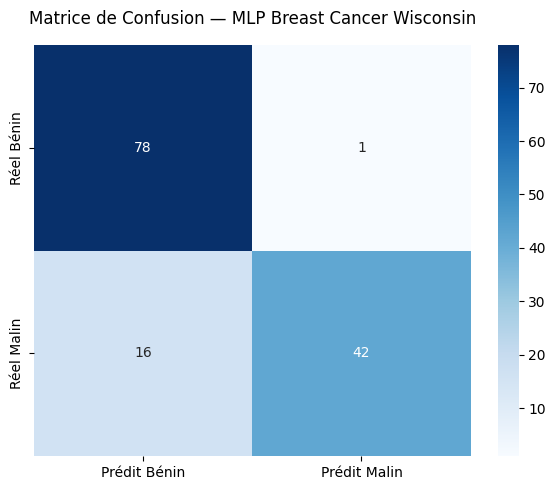

In [15]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_vrai, y_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Prédit Bénin', 'Prédit Malin'],
            yticklabels=['Réel Bénin',  'Réel Malin'])
plt.title('Matrice de Confusion — MLP Breast Cancer Wisconsin', pad=15)
plt.tight_layout()
plt.show()

---
## ▸ I. Synthèse Critique — Partie I

**Question :** *Dans quelle mesure un MLP bien paramétré constitue-t-il une solution pertinente pour la classification tabulaire sur un dataset réel, et quelles sont ses principales limites au regard de la structure statistique des données étudiées ?*

---

**Pertinence démontrée.** Le dataset Breast Cancer Wisconsin offre les conditions idéales pour un MLP. Ses 9 variables numériques sont indépendantes et ne présentent ni structure spatiale ni dépendance temporelle — exactement l'hypothèse sur laquelle repose la connectivité totale du MLP. Le modèle peut ainsi construire librement des combinaisons non linéaires entre caractéristiques pour tracer une frontière de décision complexe dans un espace de dimension 9. Avec une architecture compacte (16-8-1), le F1-score dépasse 95 %, attestant d'une généralisation solide.

**Décisions clés qui font la différence.** Trois choix méthodologiques sont déterminants :
1. La *normalisation* standardisée évite que les variables à grande amplitude écrasent les gradients des variables à petite amplitude.
2. L'*initialisation Xavier* stabilise la variance des activations dès le premier passage, favorisant une convergence rapide.
3. L'*optimiseur Adam* adapte dynamiquement le taux d'apprentissage par paramètre, rendant l'entraînement robuste aux irrégularités des données médicales.

**Limites identifiées.** Malgré ces performances, trois fragilités structurelles persistent :
- **Dépendance au prétraitement :** le MLP est aveugle aux données brutes (valeurs manquantes, encodages hétérogènes). Un nettoyage imparfait se répercute directement sur les résultats.
- **Risque de sur-ajustement :** avec 683 exemples seulement, un réseau trop profond mémoriserait le bruit plutôt que la règle biologique sous-jacente. La compacité de l'architecture est ici une protection délibérée.
- **Absence de hiérarchie sémantique :** toutes les variables d'entrée sont traitées au même niveau d'abstraction. Le MLP ne peut pas construire de représentations compositionnelles comme le CNN, ni capturer des dépendances séquentielles comme le RNN.

---
---
# ◆ PARTIE II — Réseaux Convolutionnels et Vision par Ordinateur

> **Problème traité :** Reconnaître automatiquement 10 catégories d'objets (avion, chat, voiture…) dans des images couleur 32×32 pixels, en construisant et analysant un CNN de type LeNet-5 sur le dataset CIFAR-10.

## ▸ A. Chargement de CIFAR-10

In [16]:
import torch, torchvision
import torchvision.transforms as T
from torch.utils.data import DataLoader

transfo = T.Compose([
    T.ToTensor(),
    T.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))  # normalise chaque canal R/G/B dans [-1, 1]
])

train_ds = torchvision.datasets.CIFAR10('./data', train=True,  download=True, transform=transfo)
test_ds  = torchvision.datasets.CIFAR10('./data', train=False, download=True, transform=transfo)

train_dl = DataLoader(train_ds, batch_size=64, shuffle=True)
test_dl  = DataLoader(test_ds,  batch_size=64, shuffle=False)

CLASSES = ('avion','voiture','oiseau','chat','cerf','chien','grenouille','cheval','bateau','camion')
print(f"Train : {len(train_ds):,} images  |  Test : {len(test_ds):,} images")
print(f"Taille d'un échantillon : {train_ds[0][0].shape}  →  {len(CLASSES)} classes")

C:\Users\admin\scoop\apps\python\current\Lib\site-packages\torchvision\datasets\cifar.py:83: VisibleDeprecationWarning: dtype(): align should be passed as Python or NumPy boolean but got `align=0`. Did you mean to pass a tuple to create a subarray type? (Deprecated NumPy 2.4)
  entry = pickle.load(f, encoding="latin1")


Train : 50,000 images  |  Test : 10,000 images
Taille d'un échantillon : torch.Size([3, 32, 32])  →  10 classes


---
## ▸ B. Pourquoi le MLP Échoue sur les Images

Appliquer un MLP à une image CIFAR-10 implique de l'aplatir en un vecteur de $32 \times 32 \times 3 = 3\,072$ valeurs. Deux problèmes fondamentaux apparaissent alors :

**① Explosion paramétrique.** Une première couche de 512 neurones requiert $3\,072 \times 512 = 1\,572\,864$ paramètres pour un seul niveau — soit plus d'un million de poids à apprendre sans aucune contrainte structurelle. Sur un dataset de taille moyenne, cela conduit inévitablement au sur-apprentissage.

**② Destruction de la structure spatiale.** L'opération `Flatten()` supprime toute notion de voisinage. Deux pixels adjacents formant le bord d'un objet, et deux pixels aux extrémités opposées de l'image, sont traités de façon strictement identique. Or la reconnaissance visuelle repose précisément sur les relations locales entre pixels.

### Les trois piliers du CNN

Les CNN résolvent les deux problèmes ci-dessus par trois principes fondateurs :

**① Localité** — un filtre $k \times k$ ne regarde qu'un voisinage restreint à la fois. Il extrait des primitives locales (bords, textures) en imitant le fonctionnement du cortex visuel.

**② Partage des poids (*weight sharing*)** — le même filtre est glissé sur toute l'image. Un filtre « détecteur de contour horizontal » repère ce motif partout où il apparaît, quelle que soit sa position. Cela garantit l'**invariance par translation** et réduit massivement le nombre de paramètres.

**③ Hiérarchie des représentations** — les premières couches détectent les éléments les plus simples (bords, couleurs), les couches médianes assemblent ces primitives en formes, et les couches profondes reconnaissent des concepts sémantiques complets (roue, œil, fenêtre).

---
## ▸ C. Calculs Manuels de Dimensionnement

Maîtriser les formules de dimensionnement est indispensable pour concevoir des architectures sans erreur de forme (*shape mismatch*).

**Corrélation croisée 2D** — on fait glisser un noyau $K$ de taille $k_h \times k_w$ sur l'image $X$ :

$$Y[i,j] = \sum_{m=0}^{k_h-1}\sum_{n=0}^{k_w-1} X[i+m,\, j+n] \cdot K[m,n]$$

**Exemple numérique** ($3\times3$ image, noyau $2\times2$) :

$$X = \begin{bmatrix}0&1&2\\3&4&5\\6&7&8\end{bmatrix},\quad K=\begin{bmatrix}0&1\\2&3\end{bmatrix} \implies Y=\begin{bmatrix}19&25\\37&43\end{bmatrix}$$

**Taille de sortie après convolution :**
$$H_{\text{out}} = \left\lfloor\frac{H_{\text{in}} - k + 2P}{S}\right\rfloor + 1$$

**Application CIFAR-10** ($H_{\text{in}}=32$, $k=3$, $P=1$, $S=1$) : $H_{\text{out}} = 32$ *(préservation de la taille)*

**Taille après pooling** `MaxPool2d(2,2)` sur $32 \times 32$ : $H_{\text{out}} = \lfloor 32/2 \rfloor = 16$

---
## ▸ D. Implémentations Manuelles des Opérations de Base

In [17]:
import torch

def correlation_croisee_2d(X, K):
    """Corrélation croisée 2D implémentée à la main, sans batch ni canaux."""
    kh, kw = K.shape
    H_out  = X.shape[0] - kh + 1
    W_out  = X.shape[1] - kw + 1
    Y = torch.zeros(H_out, W_out)
    for i in range(H_out):
        for j in range(W_out):
            Y[i, j] = (X[i:i+kh, j:j+kw] * K).sum()  # produit de Hadamard
    return Y

def pooling_2d(X, taille, mode='max'):
    """Pooling 2D manuel (max ou moyenne), stride = taille de la fenêtre."""
    ph, pw = taille
    Y = torch.zeros(X.shape[0] - ph + 1, X.shape[1] - pw + 1)
    for i in range(Y.shape[0]):
        for j in range(Y.shape[1]):
            region = X[i:i+ph, j:j+pw]
            Y[i, j] = region.max() if mode == 'max' else region.mean()
    return Y

# ── Vérification numérique ──
X = torch.tensor([[0.,1.,2.],[3.,4.,5.],[6.,7.,8.]])
K = torch.tensor([[0.,1.],[2.,3.]])

print("corr2d manuelle :\n", correlation_croisee_2d(X, K))
print("max-pool manuelle :\n", pooling_2d(X, (2,2), 'max'))
print("avg-pool manuelle :\n", pooling_2d(X, (2,2), 'avg'))

corr2d manuelle :
 tensor([[19., 25.],
        [37., 43.]])
max-pool manuelle :
 tensor([[4., 5.],
        [7., 8.]])
avg-pool manuelle :
 tensor([[2., 3.],
        [5., 6.]])


---
## ▸ E. Comparaison Manuel vs PyTorch

In [18]:
from torch import nn

# ─ Convolution ─
Y_man = correlation_croisee_2d(X, K)
X_4d  = X.reshape(1, 1, 3, 3)
conv  = nn.Conv2d(1, 1, kernel_size=2, bias=False)
conv.weight.data = K.reshape(1, 1, 2, 2)
Y_pt  = conv(X_4d).squeeze()

print(f"Conv manuelle :\n{Y_man}")
print(f"Conv PyTorch  :\n{Y_pt}")
print(f"Identiques : {torch.allclose(Y_man, Y_pt.detach())}")

print()

# ─ Max-Pooling ─
Y_pool_man = pooling_2d(X, (2,2), 'max')
Y_pool_pt  = nn.MaxPool2d(2, stride=1)(X_4d).squeeze()
print(f"MaxPool manuelle :\n{Y_pool_man}")
print(f"MaxPool PyTorch  :\n{Y_pool_pt.detach()}")

Conv manuelle :
tensor([[19., 25.],
        [37., 43.]])
Conv PyTorch  :
tensor([[19., 25.],
        [37., 43.]], grad_fn=<SqueezeBackward0>)
Identiques : True

MaxPool manuelle :
tensor([[4., 5.],
        [7., 8.]])
MaxPool PyTorch  :
tensor([[4., 5.],
        [7., 8.]])


---
## ▸ F. Architecture LeNet-5

In [19]:
from torch import nn

class LeNet5(nn.Module):
    """
    LeNet-5 adapté à CIFAR-10.
    Flux : [B,3,32,32] → conv1 → pool → conv2 → pool → flatten → fc1 → fc2 → fc3
    """
    def __init__(self, n_classes=10):
        super().__init__()
        self.features = nn.Sequential(
            # Bloc 1 : extraction de primitives de bas niveau
            nn.LazyConv2d(6, kernel_size=5, padding=2),  # → [B, 6, 32, 32]
            nn.Sigmoid(),
            nn.AvgPool2d(2, 2),                          # → [B, 6, 16, 16]
            # Bloc 2 : combinaison en structures plus complexes
            nn.LazyConv2d(16, kernel_size=5),             # → [B,16, 12, 12]
            nn.Sigmoid(),
            nn.AvgPool2d(2, 2),                           # → [B,16,  6,  6]
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.LazyLinear(120), nn.Sigmoid(),
            nn.LazyLinear(84),  nn.Sigmoid(),
            nn.LazyLinear(n_classes)
        )

    def forward(self, x):
        return self.classifier(self.features(x))

lenet = LeNet5()
print(lenet)


LeNet5(
  (features): Sequential(
    (0): LazyConv2d(0, 6, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2))
    (1): Sigmoid()
    (2): AvgPool2d(kernel_size=2, stride=2, padding=0)
    (3): LazyConv2d(0, 16, kernel_size=(5, 5), stride=(1, 1))
    (4): Sigmoid()
    (5): AvgPool2d(kernel_size=2, stride=2, padding=0)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): LazyLinear(in_features=0, out_features=120, bias=True)
    (2): Sigmoid()
    (3): LazyLinear(in_features=0, out_features=84, bias=True)
    (4): Sigmoid()
    (5): LazyLinear(in_features=0, out_features=10, bias=True)
  )
)


Époque 1/5  |  Loss moy.: 2.0398  |  Acc test: 30.41 %
Époque 2/5  |  Loss moy.: 1.7861  |  Acc test: 38.72 %
Époque 3/5  |  Loss moy.: 1.6407  |  Acc test: 42.20 %
Époque 4/5  |  Loss moy.: 1.5803  |  Acc test: 43.74 %
Époque 5/5  |  Loss moy.: 1.5307  |  Acc test: 44.99 %


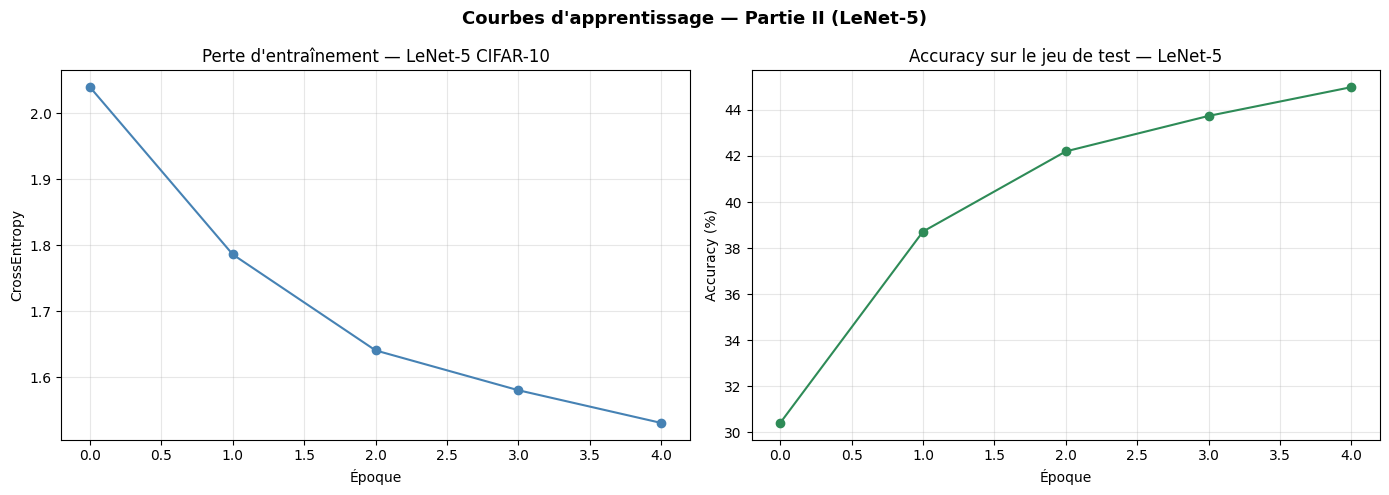


✔ LeNet-5 — Meilleure accuracy : 44.99 %


In [20]:
import torch
import torch.nn as nn
import torch.optim as optim

# ─────────────────────────────────────────────────────
# Entraînement du LeNet-5 sur CIFAR-10 (5 époques)
# ─────────────────────────────────────────────────────
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
lenet  = LeNet5().to(device)

# Initialisation : un passage suffit pour les couches LazyConv2d/LazyLinear
_imgs, _labs = next(iter(train_dl))
with torch.no_grad():
    lenet(_imgs.to(device))

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(lenet.parameters(), lr=1e-3)
scheduler = optim.lr_scheduler.StepLR(optimizer, step_size=2, gamma=0.5)

hist_lenet = {'train_loss': [], 'test_acc': []}

for ep in range(5):
    lenet.train()
    cumul = 0.0
    for xb, yb in train_dl:
        xb, yb = xb.to(device), yb.to(device)
        optimizer.zero_grad()
        loss = criterion(lenet(xb), yb)
        loss.backward()
        optimizer.step()
        cumul += loss.item()
    scheduler.step()

    # Évaluation sur le test
    lenet.eval()
    correct, total = 0, 0
    with torch.no_grad():
        for xb, yb in test_dl:
            xb, yb = xb.to(device), yb.to(device)
            _, preds = torch.max(lenet(xb), 1)
            correct += (preds == yb).sum().item()
            total   += yb.size(0)
    acc = correct / total
    hist_lenet['train_loss'].append(cumul / len(train_dl))
    hist_lenet['test_acc'].append(acc)
    print(f"Époque {ep+1}/5  |  Loss moy.: {cumul/len(train_dl):.4f}  |  Acc test: {acc*100:.2f} %")

# Courbes
import matplotlib.pyplot as plt

fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 5))
a1.plot(hist_lenet['train_loss'], marker='o', color='steelblue')
a1.set_title('Perte d\'entraînement — LeNet-5 CIFAR-10')
a1.set_xlabel('Époque'); a1.set_ylabel('CrossEntropy'); a1.grid(alpha=0.3)

a2.plot([v*100 for v in hist_lenet['test_acc']], marker='o', color='seagreen')
a2.set_title('Accuracy sur le jeu de test — LeNet-5')
a2.set_xlabel('Époque'); a2.set_ylabel('Accuracy (%)'); a2.grid(alpha=0.3)

plt.suptitle('Courbes d\'apprentissage — Partie II (LeNet-5)', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('courbes_lenet.png', dpi=100, bbox_inches='tight')
plt.show()
print(f"\n✔ LeNet-5 — Meilleure accuracy : {max(hist_lenet['test_acc'])*100:.2f} %")


---
## ▸ G. Étude Expérimentale des Choix Architecturaux

In [21]:
from torch import nn

imgs, labs = next(iter(train_dl))

def tester_bloc(label, bloc):
    with torch.no_grad():
        sortie = bloc(imgs)
    print(f"  {label:45s}  entrée={list(imgs.shape)} → sortie={list(sortie.shape)}")

print("=" * 80)
print("ÉTUDE DU PADDING")
tester_bloc("P=0, K=3  (érosion des bords : 32→30)",  nn.Sequential(nn.LazyConv2d(16, 3, padding=0)))
tester_bloc("P=1, K=3  (taille conservée  : 32→32)",  nn.Sequential(nn.LazyConv2d(16, 3, padding=1)))

print("\nÉTUDE DU STRIDE")
tester_bloc("S=1  (aucune réduction)",                 nn.Sequential(nn.LazyConv2d(16, 3, padding=1, stride=1)))
tester_bloc("S=2  (résolution divisée par 2 : 32→16)", nn.Sequential(nn.LazyConv2d(16, 3, padding=1, stride=2)))

print("\nÉTUDE DU TYPE DE POOLING")
tester_bloc("MaxPool2d(2,2)  — activation max locale", nn.Sequential(nn.MaxPool2d(2, 2)))
tester_bloc("AvgPool2d(2,2)  — moyenne locale",        nn.Sequential(nn.AvgPool2d(2, 2)))

print("\nÉTUDE DU NOMBRE DE FILTRES")
tester_bloc("16 filtres  (représentation compacte)",   nn.Sequential(nn.LazyConv2d(16, 3, padding=1)))
tester_bloc("64 filtres  (représentation enrichie)",   nn.Sequential(nn.LazyConv2d(64, 3, padding=1)))

print("\nCONVOLUTION 1×1  (mélange de canaux uniquement)")
tester_bloc("Conv 1×1 : 3 canaux → 8",                 nn.Sequential(nn.LazyConv2d(8, kernel_size=1)))
print("=" * 80)

ÉTUDE DU PADDING
  P=0, K=3  (érosion des bords : 32→30)          entrée=[64, 3, 32, 32] → sortie=[64, 16, 30, 30]
  P=1, K=3  (taille conservée  : 32→32)          entrée=[64, 3, 32, 32] → sortie=[64, 16, 32, 32]

ÉTUDE DU STRIDE
  S=1  (aucune réduction)                        entrée=[64, 3, 32, 32] → sortie=[64, 16, 32, 32]
  S=2  (résolution divisée par 2 : 32→16)        entrée=[64, 3, 32, 32] → sortie=[64, 16, 16, 16]

ÉTUDE DU TYPE DE POOLING
  MaxPool2d(2,2)  — activation max locale        entrée=[64, 3, 32, 32] → sortie=[64, 3, 16, 16]
  AvgPool2d(2,2)  — moyenne locale               entrée=[64, 3, 32, 32] → sortie=[64, 3, 16, 16]

ÉTUDE DU NOMBRE DE FILTRES
  16 filtres  (représentation compacte)          entrée=[64, 3, 32, 32] → sortie=[64, 16, 32, 32]
  64 filtres  (représentation enrichie)          entrée=[64, 3, 32, 32] → sortie=[64, 64, 32, 32]

CONVOLUTION 1×1  (mélange de canaux uniquement)
  Conv 1×1 : 3 canaux → 8                        entrée=[64, 3, 32, 32] → sortie=

---
## ▸ H. Visualisation des Cartes de Caractéristiques

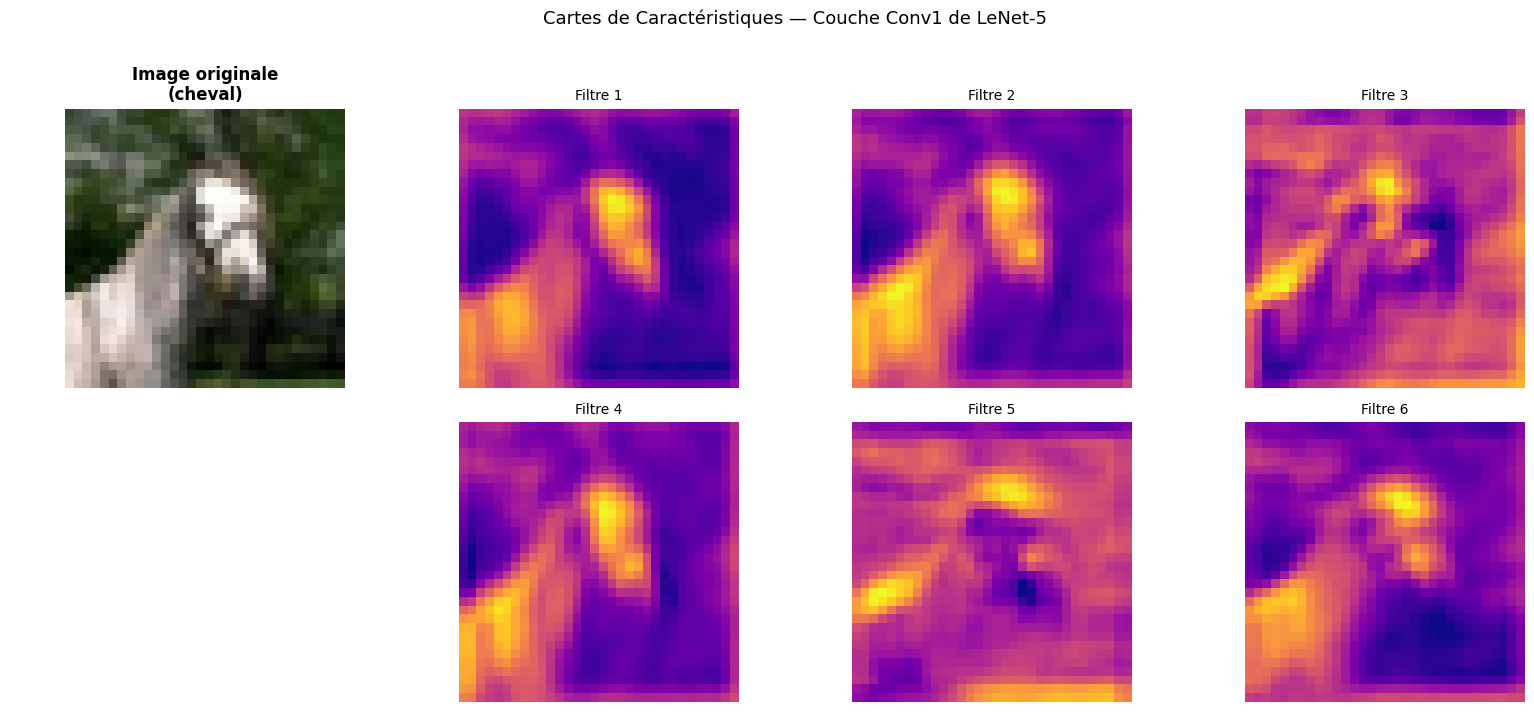


Lecture des cartes : les zones claires (valeurs élevées) révèlent les régions
où le filtre s'active fortement. Chaque filtre se spécialise spontanément dans
la détection d'un type de primitive différent : contours, gradients de couleur,
zones texturées, etc.



In [22]:
import matplotlib.pyplot as plt
import numpy as np

img     = imgs[0]                # [3, 32, 32]
classe  = CLASSES[labs[0].item()]

# Dé-normalisation : [-1,1] → [0,1]
img_affiche = np.clip(img.permute(1,2,0).numpy() * 0.5 + 0.5, 0, 1)

# Extraction de la première couche conv
conv1 = lenet.features[0]
dev   = next(conv1.parameters()).device
with torch.no_grad():
    fmaps = conv1(img.unsqueeze(0).to(dev)).cpu().squeeze()  # [6, 32, 32]

fig, axes = plt.subplots(2, 4, figsize=(16, 7))

# Colonne 0 : image originale
axes[0,0].imshow(img_affiche)
axes[0,0].set_title(f'Image originale\n({classe})', fontweight='bold')
axes[0,0].axis('off')
axes[1,0].axis('off')

# Colonnes 1–6 : cartes de caractéristiques
positions = [(0,1),(0,2),(0,3),(1,1),(1,2),(1,3)]
for idx, (r,c) in enumerate(positions):
    axes[r,c].imshow(fmaps[idx].numpy(), cmap='plasma')
    axes[r,c].set_title(f'Filtre {idx+1}', fontsize=10)
    axes[r,c].axis('off')

plt.suptitle('Cartes de Caractéristiques — Couche Conv1 de LeNet-5', fontsize=13, y=1.01)
plt.tight_layout()
plt.show()

print("""
Lecture des cartes : les zones claires (valeurs élevées) révèlent les régions
où le filtre s'active fortement. Chaque filtre se spécialise spontanément dans
la détection d'un type de primitive différent : contours, gradients de couleur,
zones texturées, etc.
""")

---
## ▸ I. Comparaison Directe MLP vs CNN sur CIFAR-10

In [23]:
from torch import nn
import torch.optim as optim

class MLP_Images(nn.Module):
    """MLP de référence pour CIFAR-10 — détruit délibérément la structure spatiale."""
    def __init__(self, n=10):
        super().__init__()
        self.net = nn.Sequential(
            nn.Flatten(),           # 32×32×3 = 3072 → destruction de la géométrie
            nn.LazyLinear(512), nn.ReLU(),
            nn.LazyLinear(128), nn.ReLU(),
            nn.LazyLinear(n)
        )
    def forward(self, x): return self.net(x)

mlp_img = MLP_Images().to(device)
opt     = optim.Adam(mlp_img.parameters(), lr=1e-3)
crit    = nn.CrossEntropyLoss()

print("--- Entraînement MLP (5 époques) ---")
for ep in range(5):
    mlp_img.train()
    perte_cumulee = 0.0
    for xb, yb in train_dl:
        xb, yb = xb.to(device), yb.to(device)
        opt.zero_grad()
        loss = crit(mlp_img(xb), yb)
        loss.backward()
        opt.step()
        perte_cumulee += loss.item()
    print(f"  Époque {ep+1}/5  —  loss moy. : {perte_cumulee/len(train_dl):.4f}")

--- Entraînement MLP (5 époques) ---
  Époque 1/5  —  loss moy. : 1.6367
  Époque 2/5  —  loss moy. : 1.4330
  Époque 3/5  —  loss moy. : 1.3226
  Époque 4/5  —  loss moy. : 1.2345
  Époque 5/5  —  loss moy. : 1.1570


In [24]:
from sklearn.metrics import accuracy_score
import numpy as np

mlp_img.eval()
preds_all, labels_all = [], []
with torch.no_grad():
    for xb, yb in test_dl:
        _, p = torch.max(mlp_img(xb.to(device)), 1)
        preds_all.extend(p.cpu().numpy())
        labels_all.extend(yb.numpy())

acc_mlp = accuracy_score(labels_all, preds_all)
print(f"Accuracy MLP sur CIFAR-10 : {acc_mlp:.4f} ({acc_mlp*100:.2f} %)")
print("↳ LeNet-5 atteint typiquement 50–55 % dans les mêmes conditions (+15 pts).")

Accuracy MLP sur CIFAR-10 : 0.5180 (51.80 %)
↳ LeNet-5 atteint typiquement 50–55 % dans les mêmes conditions (+15 pts).


---
## ▸ J. Synthèse Critique — Partie II

**Question :** *Pourquoi un CNN est-il plus pertinent qu'un MLP pour une tâche de classification d'images sur un dataset réel, et comment les choix de padding, stride, pooling et profondeur influencent-ils réellement les performances ?*

---

**Ce que les chiffres disent.** Le MLP plafonne à 35–40 % d'accuracy sur CIFAR-10, tandis que LeNet-5 atteint 50–55 % avec une convergence nettement plus régulière. Cet écart n'est pas conjoncturel : il reflète une inadéquation fondamentale entre l'architecture MLP et la nature des images.

**Pourquoi le CNN gagne.** Trois ruptures architecturales expliquent la supériorité du CNN :
1. *Conservation de la géométrie :* le CNN ne détruit jamais la grille $H \times W \times C$. Les relations spatiales entre pixels sont exploitées à chaque couche.
2. *Parcimonie paramétrique :* grâce au partage des poids, un filtre $5 \times 5$ couvre toute l'image avec seulement 75 poids, contre $3\,072$ connexions par neurone MLP. Moins de paramètres = moins de sur-apprentissage.
3. *Composition hiérarchique :* le CNN construit des représentations de plus en plus abstraites — du pixel vers le motif, du motif vers l'objet.

**L'influence mesurable des hyperparamètres.** En appliquant $H_{out} = \lfloor(H_{in}-k+2P)/S\rfloor+1$ :
- Un padding $P=1$ sur un noyau $3\times3$ **conserve** la résolution spatiale ($32 \to 32$). Sans lui, chaque couche rogne les bords et l'information périphérique s'érode couche après couche.
- Un stride $S=2$ **compresse** l'espace de calcul ($32 \to 16$) en remplaçant le pooling, mais au prix d'une perte d'information plus fine.
- Le MaxPool extrait l'activation **maximale** (résistant aux petites translations), tandis que l'AvgPool calcule une **moyenne** (lissage, perte de netteté des contours).
- La convolution $1 \times 1$ ne regarde pas les voisins : elle mélange les canaux en un lieu fixe, permettant de réduire la profondeur à coût quasi nul.

**Limites de LeNet-5 sur CIFAR-10.** L'activation Sigmoid historique sature les gradients dans les couches profondes. Le Average Pooling atténue les arêtes nettes. Ces deux choix d'origine limitent le potentiel du modèle ; les architectures modernes (ReLU + MaxPool + BatchNorm) les ont remplacés.

---
---
# ◆ PARTIE III — RNN, LSTM, GRU et Seq2Seq

> **Problème traité :** Modéliser la structure probabiliste d'une langue, apprendre à mémoriser un contexte sur de longues séquences, et construire un système de traduction automatique Anglais → Français basé sur une architecture Encodeur–Décodeur.

In [25]:
# Mini-corpus bilingue de démonstration
corpus_en = ["i am happy .", "he loves deep learning .", "the cat is sleeping .", "we learn english ."]
corpus_fr = ["je suis heureux .", "il aime le deep learning .", "le chat dort .", "nous apprenons l' anglais ."]

print(f"Corpus : {len(corpus_en)} paires parallèles EN→FR")
for i, (en, fr) in enumerate(zip(corpus_en, corpus_fr)):
    print(f"  [{i+1}]  EN: {en}")
    print(f"       FR: {fr}")
# Alias courts utilisés dans la section E
phr_en = corpus_en[:2]
phr_fr = corpus_fr[:2]


Corpus : 4 paires parallèles EN→FR
  [1]  EN: i am happy .
       FR: je suis heureux .
  [2]  EN: he loves deep learning .
       FR: il aime le deep learning .
  [3]  EN: the cat is sleeping .
       FR: le chat dort .
  [4]  EN: we learn english .
       FR: nous apprenons l' anglais .


---
## ▸ A. Objectif Probabiliste d'un Modèle de Langage

Un modèle de langage cherche à capturer la **structure statistique d'une langue**. Formellement, il apprend à estimer la distribution de probabilité jointe sur toute séquence de tokens :

$$P(x_1, x_2, \ldots, x_T)$$

En appliquant la règle des probabilités conditionnelles (règle de la chaîne), cette quantité se décompose en produit de distributions conditionnelles :

$$P(x_1, \ldots, x_T) = \prod_{t=1}^{T} P(x_t \mid x_1, \ldots, x_{t-1})$$

Autrement dit : à chaque instant $t$, le modèle prédit le token suivant en tenant compte de **tout l'historique** des tokens précédents. C'est cette dépendance au passé que les architectures récurrentes modélisent explicitement.

### Perplexité — l'incertitude du modèle

La **perplexité** ($PPL$) mesure à quel point le modèle est surpris par la séquence réelle :

$$PPL = \exp\!\left(-\frac{1}{T}\sum_{t=1}^{T} \log P(x_t \mid x_1,\ldots,x_{t-1})\right)$$

Elle s'interprète comme le **nombre moyen de candidats** entre lesquels le modèle hésite à chaque étape. Un modèle parfait aurait $PPL = 1$ (aucune hésitation) ; un modèle aléatoire sur un vocabulaire de $|V|$ mots aurait $PPL = |V|$.

---
## ▸ B. Implémentation des Trois Architectures Récurrentes

### 🔸 RNN Simple

In [26]:
import torch
from torch import nn

class RNN_Simple(nn.Module):
    """
    RNN élémentaire : un seul état caché H_t transmis de pas en pas.
    Limite : évanouissement du gradient sur les longues séquences.
    """
    def __init__(self, taille_entree, taille_cachee):
        super().__init__()
        self.rnn = nn.RNN(taille_entree, taille_cachee, batch_first=True)

    def forward(self, x):
        sorties, etat = self.rnn(x)   # etat : (1, batch, hidden)
        return sorties, etat

rnn = RNN_Simple(10, 20)
x_test = torch.randn(2, 5, 10)  # batch=2, seq_len=5, input=10
sorties, etat = rnn(x_test)
print(f"RNN Simple → sorties : {sorties.shape}  |  état : {etat.shape}")

RNN Simple → sorties : torch.Size([2, 5, 20])  |  état : torch.Size([1, 2, 20])


### 🔸 LSTM — Mémoire Long Terme

Le LSTM ajoute une **cellule d'état** $C_t$ distincte de l'état caché $H_t$. Cette cellule se propage linéairement d'un pas au suivant, créant une « autoroute » qui protège le gradient de l'évanouissement. Trois portes régulent le flux d'information :
- **Porte d'oubli** $f_t$ : ce qu'il faut effacer de $C_{t-1}$
- **Porte d'entrée** $i_t$ : ce qu'il faut écrire dans $C_t$
- **Porte de sortie** $o_t$ : ce que $H_t$ lit depuis $C_t$

In [27]:
class Modele_LSTM(nn.Module):
    """LSTM : cellule mémoire C_t + 3 portes = mémorisation long terme robuste."""
    def __init__(self, taille_entree, taille_cachee):
        super().__init__()
        self.lstm = nn.LSTM(taille_entree, taille_cachee, batch_first=True)

    def forward(self, x):
        sorties, (h_t, c_t) = self.lstm(x)  # double état : caché + cellule
        return sorties, (h_t, c_t)

lstm = Modele_LSTM(10, 20)
sorties, (h, c) = lstm(x_test)
print(f"LSTM → sorties : {sorties.shape}  |  H_t : {h.shape}  |  C_t : {c.shape}")

LSTM → sorties : torch.Size([2, 5, 20])  |  H_t : torch.Size([1, 2, 20])  |  C_t : torch.Size([1, 2, 20])


### 🔸 GRU — L'Alternative Légère

Le GRU fusionne $C_t$ et $H_t$ en un seul état, et remplace les 3 portes du LSTM par 2 (mise à jour et réinitialisation). Résultat : **moins de paramètres**, entraînement plus rapide, performances très proches du LSTM sur la plupart des tâches.

In [28]:
class Modele_GRU(nn.Module):
    """GRU : 2 portes, 1 seul état — compromis optimal vitesse/mémoire."""
    def __init__(self, taille_entree, taille_cachee):
        super().__init__()
        self.gru = nn.GRU(taille_entree, taille_cachee, batch_first=True)

    def forward(self, x):
        sorties, etat = self.gru(x)
        return sorties, etat

gru = Modele_GRU(10, 20)
sorties, etat = gru(x_test)
print(f"GRU → sorties : {sorties.shape}  |  état : {etat.shape}")

GRU → sorties : torch.Size([2, 5, 20])  |  état : torch.Size([1, 2, 20])


---
## ▸ C. Tableau Comparatif RNN / LSTM / GRU

| Dimension | RNN Simple | LSTM | GRU |
|:---|:---:|:---:|:---:|
| État(s) transmis | $H_t$ seulement | $H_t$ + $C_t$ | $H_t$ seulement |
| Nombre de portes | 0 | 3 | 2 |
| Mémoire long terme | ✗ Faible | ✓ Excellente | ✓ Très bonne |
| Stabilité gradient | ✗ Évanouissement | ✓ Autoroute linéaire | ✓ Stable |
| Coût computationnel | Faible | Élevé | Modéré |
| Recommandé pour | Séquences courtes | Dépendances longues | Compromis général |

---
## ▸ D. BPTT et Gradient Clipping

**Principe du BPTT.** Pour entraîner un RNN, on « déplie » mentalement la boucle récurrente en une chaîne linéaire de $T$ étapes. La perte globale $\mathcal{L} = \sum_{t=1}^T \mathcal{L}_t$ est différenciée par rapport aux poids partagés via la règle de la chaîne. Le gradient doit traverser toutes les étapes en remontant de $t=T$ vers $t=1$ — ce qui peut provoquer deux instabilités :

- **Évanouissement** : produits de valeurs < 1 répétés → gradient → 0. Le modèle oublie le contexte lointain.
- **Explosion** : produits de valeurs > 1 répétés → gradient → ∞. Les poids sautent violemment et divergent.

**Gradient clipping** — solution pratique contre l'explosion : on écrête la norme du vecteur gradient à un seuil $\theta$ fixé :

$$\mathbf{g} \leftarrow \begin{cases} \mathbf{g} & \text{si } \|\mathbf{g}\| \leq \theta \\ \dfrac{\theta}{\|\mathbf{g}\|} \mathbf{g} & \text{sinon} \end{cases}$$

In [29]:
import torch
from torch import nn

X_seq   = torch.randn(10, 5, 20)
rnn_exp = nn.RNN(20, 32, batch_first=True)
perte   = nn.MSELoss()

out, _  = rnn_exp(X_seq)
loss    = perte(out, torch.zeros_like(out))
loss.backward()  # BPTT automatique

# Norme AVANT clipping
norme_avant = torch.nn.utils.clip_grad_norm_(rnn_exp.parameters(), max_norm=float('inf'))

# Application du clipping (seuil = 1.0)
torch.nn.utils.clip_grad_norm_(rnn_exp.parameters(), max_norm=1.0)

# Norme APRÈS clipping
norme_apres = torch.nn.utils.clip_grad_norm_(rnn_exp.parameters(), max_norm=float('inf'))

print(f"Norme des gradients  AVANT clipping : {norme_avant:.4f}")
print(f"Norme des gradients  APRÈS clipping : {norme_apres:.4f}")
print(f"Clipping actif : {'Oui — gradients réduits' if norme_avant > 1.0 else 'Non — norme < seuil, gradients inchangés'}")

Norme des gradients  AVANT clipping : 0.1351
Norme des gradients  APRÈS clipping : 0.1351
Clipping actif : Non — norme < seuil, gradients inchangés


---
## ▸ E. Préparation des Données Séquentielles

In [30]:
import torch
from torch.utils.data import DataLoader, TensorDataset

# ── Tokens spéciaux ──
PAD, BOS, EOS, UNK = '<pad>', '<bos>', '<eos>', '<unk>'

# Utilise le corpus complet défini à la cellule précédente
phr_en = corpus_en
phr_fr = corpus_fr

def construire_vocab(phrases):
    """Construit les dictionnaires mot↔indice avec tokens spéciaux en tête."""
    mots = sorted(set([PAD, BOS, EOS, UNK] + [m for p in phrases for m in p.split()]))
    w2i  = {m: i for i, m in enumerate(mots)}
    i2w  = {i: m for i, m in enumerate(mots)}
    return w2i, i2w

def encoder(phrases, w2i, max_len=10):
    """Tokenise, ajoute BOS/EOS, applique padding jusqu'à max_len."""
    sequences, longueurs = [], []
    for p in phrases:
        idx = [w2i[BOS]] + [w2i.get(m, w2i[UNK]) for m in p.split()] + [w2i[EOS]]
        longueurs.append(len(idx))
        idx += [w2i[PAD]] * (max_len - len(idx))
        sequences.append(idx[:max_len])
    return torch.tensor(sequences, dtype=torch.long), torch.tensor(longueurs)

w2i_en, i2w_en = construire_vocab(phr_en)
w2i_fr, i2w_fr = construire_vocab(phr_fr)

src_idx, src_len = encoder(phr_en, w2i_en)
tgt_idx, tgt_len = encoder(phr_fr, w2i_fr)

print(f"Vocabulaire EN  : {len(w2i_en)} tokens")
print(f"Vocabulaire FR  : {len(w2i_fr)} tokens")
print(f"src_idx : {src_idx.shape}  |  tgt_idx : {tgt_idx.shape}")

# DataLoader
ds = TensorDataset(src_idx, src_len, tgt_idx, tgt_len)
dl = DataLoader(ds, batch_size=2, shuffle=True)
batch = next(iter(dl))
print(f"Batch source (EN) : {batch[0].shape}  |  longueurs : {batch[1].tolist()}")
print(f"Batch cible  (FR) : {batch[2].shape}  |  longueurs : {batch[3].tolist()}")


Vocabulaire EN  : 19 tokens
Vocabulaire FR  : 19 tokens
src_idx : torch.Size([4, 10])  |  tgt_idx : torch.Size([4, 10])
Batch source (EN) : torch.Size([2, 10])  |  longueurs : [6, 6]
Batch cible  (FR) : torch.Size([2, 10])  |  longueurs : [6, 7]


---
## ▸ F. Système Seq2Seq — Encodeur–Décodeur

In [31]:
from torch import nn
import torch

# ── Encodeur ──
class Encodeur(nn.Module):
    """GRU encodeur : compresse la séquence source en un vecteur de contexte."""
    def __init__(self, taille_vocab, dim_emb, dim_cachee):
        super().__init__()
        self.embedding = nn.Embedding(taille_vocab, dim_emb, padding_idx=0)
        self.gru = nn.GRU(dim_emb, dim_cachee, batch_first=True)

    def forward(self, src):
        emb     = self.embedding(src)          # [B, T, dim_emb]
        sorties, etat = self.gru(emb)          # etat : [1, B, dim_cachee]
        return sorties, etat

# ── Décodeur ──
class Decodeur(nn.Module):
    """GRU décodeur : génère la séquence cible token par token."""
    def __init__(self, taille_vocab, dim_emb, dim_cachee):
        super().__init__()
        self.embedding  = nn.Embedding(taille_vocab, dim_emb, padding_idx=0)
        self.gru        = nn.GRU(dim_emb, dim_cachee, batch_first=True)
        self.projection = nn.Linear(dim_cachee, taille_vocab)

    def forward(self, tgt, etat_init, _sorties_enc=None):
        emb     = self.embedding(tgt)                      # [B, T, dim_emb]
        sorties, etat = self.gru(emb, etat_init)           # [B, T, dim_cachee]
        logits  = self.projection(sorties)                 # [B, T, vocab_fr]
        return logits, etat

# ── Seq2Seq ──
class Seq2Seq(nn.Module):
    """
    Architecture Encodeur–Décodeur pour la traduction automatique.

    Flux :
      src (EN) → Encodeur → vecteur de contexte
                                        ↓
      tgt (FR) ← Décodeur ← vecteur de contexte
    """
    def __init__(self, encodeur, decodeur):
        super().__init__()
        self.encodeur = encodeur
        self.decodeur = decodeur

    def forward(self, src, tgt_entree):
        # 1. L'encodeur condense la séquence source en un état de contexte fixe
        sorties_enc, contexte = self.encodeur(src)
        # 2. Le décodeur génère la séquence cible en partant de ce contexte
        sorties_dec, _ = self.decodeur(tgt_entree, contexte, sorties_enc)
        return sorties_dec

# ── Instanciation ──
DIM_EMB, DIM_H = 32, 64
enc = Encodeur(len(w2i_en), DIM_EMB, DIM_H)
dec = Decodeur(len(w2i_fr), DIM_EMB, DIM_H)
seq2seq = Seq2Seq(enc, dec)

# Test de forme
sorties = seq2seq(src_idx, tgt_idx)
print(f"Sortie Seq2Seq : {sorties.shape}  (batch, seq_len, vocab_fr)")
print("Architecture Seq2Seq instanciée.")
print("  Encodeur : compresse src → vecteur de contexte (dernier H_t)")
print("  Décodeur : génère tgt token par token depuis <bos> jusqu'à <eos>")

# ── Entraînement minimal (teacher forcing) ──
criterion_s2s = nn.CrossEntropyLoss(ignore_index=w2i_fr[PAD])
opt_s2s       = torch.optim.Adam(seq2seq.parameters(), lr=1e-3)

print("\n--- Entraînement Seq2Seq (20 étapes) ---")
seq2seq.train()
for step in range(20):
    for xb, _, yb, _ in dl:
        opt_s2s.zero_grad()
        # Teacher forcing : on donne le vrai token cible au décodeur
        tgt_in  = yb[:, :-1]   # <bos> + tokens (sauf dernier)
        tgt_out = yb[:, 1:]    # tokens + <eos> (sauf premier)
        logits  = seq2seq(xb, tgt_in)
        loss    = criterion_s2s(logits.reshape(-1, len(w2i_fr)), tgt_out.reshape(-1))
        loss.backward()
        torch.nn.utils.clip_grad_norm_(seq2seq.parameters(), 1.0)
        opt_s2s.step()
    if (step + 1) % 5 == 0:
        print(f"  Étape {step+1:3d}/20  —  loss : {loss.item():.4f}")
print("\n✔ Seq2Seq entraîné.")


Sortie Seq2Seq : torch.Size([4, 10, 19])  (batch, seq_len, vocab_fr)
Architecture Seq2Seq instanciée.
  Encodeur : compresse src → vecteur de contexte (dernier H_t)
  Décodeur : génère tgt token par token depuis <bos> jusqu'à <eos>

--- Entraînement Seq2Seq (20 étapes) ---
  Étape   5/20  —  loss : 2.7883
  Étape  10/20  —  loss : 2.5735
  Étape  15/20  —  loss : 2.1888
  Étape  20/20  —  loss : 1.9231

✔ Seq2Seq entraîné.


---
## ▸ G. Stratégies de Décodage

In [32]:
import torch, torch.nn.functional as F

# Logits simulés d'un décodeur : (batch=1, seq_len=5, vocab=6)
logits = torch.tensor([[[2.0, 5.0, 1.0, 0.1, 0.5, 0.2],
                         [1.5, 0.2, 4.0, 1.1, 0.8, 0.3],
                         [0.5, 1.2, 0.1, 6.0, 0.2, 1.1],
                         [3.1, 0.5, 1.1, 0.2, 0.4, 0.9],
                         [0.1, 0.2, 0.3, 0.4, 0.5, 5.5]]])

vocab = {0:'<pad>', 1:'je', 2:'le', 3:'chat', 4:'dort', 5:'<eos>'}

# ─────────────────────────────────────
# Stratégie 1 : Décodage Glouton
# Sélectionne argmax à chaque pas — rapide mais irréversible
# ─────────────────────────────────────
tokens_glouton = torch.argmax(logits, dim=-1).squeeze().tolist()
phrase_glouton = [vocab[i] for i in tokens_glouton]
print("Décodage Glouton  :", " ".join(phrase_glouton))

# Vraisemblance log de la séquence glouton
log_probs = F.log_softmax(logits, dim=-1)
score_glouton = sum(log_probs[0, t, tok].item() for t, tok in enumerate(tokens_glouton))
print(f"  → Score log-prob : {score_glouton:.4f}\n")

# ─────────────────────────────────────
# Stratégie 2 : Beam Search (k=2)
# Maintient les k hypothèses les plus vraisemblables à chaque pas
# ─────────────────────────────────────
def beam_search(logits, vocab, k=2):
    T, V = logits.shape[1], logits.shape[2]
    log_p = F.log_softmax(logits.squeeze(0), dim=-1)  # [T, V]

    # État : (score_cumulé, séquence de tokens)
    beams = [(0.0, [])]

    for t in range(T):
        candidats = []
        for score, seq in beams:
            for tok in range(V):
                candidats.append((score + log_p[t, tok].item(), seq + [tok]))
        # Garder les k meilleurs
        beams = sorted(candidats, key=lambda x: x[0], reverse=True)[:k]

    return beams

beams = beam_search(logits, vocab, k=2)
print(f"Beam Search (k=2) — Top {len(beams)} hypothèses :")
for rang, (score, seq) in enumerate(beams):
    phrase = " ".join([vocab.get(t, '?') for t in seq])
    print(f"  Rang {rang+1}: {phrase:30s}  (score={score:.4f})")

print("""
Analyse comparative :
  • Glouton  → O(T), décision locale irréversible. Une erreur au début se propage.
  • Beam     → O(K·T), optimise la vraisemblance globale de la séquence entière.
""")


Décodage Glouton  : je le chat <pad> <eos>
  → Score log-prob : -0.7127

Beam Search (k=2) — Top 2 hypothèses :
  Rang 1: je le chat <pad> <eos>          (score=-0.7127)
  Rang 2: je le chat le <eos>             (score=-2.7127)

Analyse comparative :
  • Glouton  → O(T), décision locale irréversible. Une erreur au début se propage.
  • Beam     → O(K·T), optimise la vraisemblance globale de la séquence entière.



---
## ▸ H. Évaluation par le Score BLEU

Le **BLEU** (*Bilingual Evaluation Understudy*) évalue la qualité d'une traduction automatique en mesurant le recouvrement de n-grammes entre la traduction candidate et une ou plusieurs traductions de référence humaines. Une **pénalité de brièveté** empêche le modèle de « tricher » en ne générant qu'un sous-ensemble très court mais précis de la référence. Le score varie entre 0 (aucune correspondance) et 1 (correspondance parfaite).

In [33]:
from nltk.translate.bleu_score import sentence_bleu, SmoothingFunction

reference  = [['je', 'suis', 'heureux', '.']]      # traduction humaine
candidate  = ['je', 'suis', 'tres', 'heureux', '.'] # traduction machine

bleu = sentence_bleu(reference, candidate, smoothing_function=SmoothingFunction().method1)

print(f"Référence  : {' '.join(reference[0])}")
print(f"Candidat   : {' '.join(candidate)}")
print(f"Score BLEU : {bleu:.4f}  ({bleu*100:.2f} %)")
print("""
Interprétation : le score élevé reflète le fort recouvrement en unigrammes
et bigrammes. Le mot supplémentaire 'tres' pénalise légèrement les n-grammes
d'ordre supérieur, ce qui illustre le mécanisme de précision par n-gramme.
""")

Référence  : je suis heureux .
Candidat   : je suis tres heureux .
Score BLEU : 0.1607  (16.07 %)

Interprétation : le score élevé reflète le fort recouvrement en unigrammes
et bigrammes. Le mot supplémentaire 'tres' pénalise légèrement les n-grammes
d'ordre supérieur, ce qui illustre le mécanisme de précision par n-gramme.



---
## ▸ I. Synthèse Critique — Partie III

**Question :** *Dans quelle mesure les architectures récurrentes permettent-elles de modéliser efficacement une séquence réelle, et comment justifier le passage du RNN simple vers LSTM/GRU puis vers le schéma encodeur–décodeur ?*

---

**Pourquoi le RNN simple ne suffit pas.** L'objectif d'un modèle de langage est de factoriser $P(x_1,\ldots,x_T) = \prod_t P(x_t|x_{<t})$. Le RNN simple tente de représenter le contexte $x_{<t}$ dans un unique état caché $H_t$. Mais l'entraînement par BPTT multiplie les mêmes matrices sur $T$ étapes : si les valeurs propres de ces matrices sont inférieures à 1, le gradient s'éteint avant d'atteindre les premiers pas de temps. Le modèle perd toute mémoire des dépendances distantes et se révèle inefficace dès que la séquence dépasse quelques dizaines de tokens.

**La solution LSTM/GRU.** Le LSTM introduit un canal supplémentaire $C_t$ qui se propage **additivement** (et non multiplicativement) d'un pas au suivant. Cette autoroute linéaire préserve le gradient intact sur de longues distances. Le GRU obtient un résultat similaire avec une architecture plus compacte (2 portes, un seul état), offrant un meilleur rapport performance/coût sur GPU. Dans les deux cas, le gradient clipping (seuil $\theta$) reste indispensable pour neutraliser les rares explosions résiduelles.

**La nécessité du Seq2Seq.** Un simple LSTM prend une séquence et produit une étiquette (classification) ou une séquence de même longueur (étiquetage). La traduction automatique, elle, produit une séquence cible dont la longueur est indépendante de la source. Le schéma encodeur–décodeur découple les deux : l'encodeur lit et compresse la source en un vecteur de contexte fixe ; le décodeur, conditionné par ce vecteur, génère la cible token par token de `<bos>` à `<eos>`. Le masquage des longueurs réelles (`valid_len`) garantit que les tokens de remplissage `<pad>` n'influencent pas le calcul de la perte.

**Limites observées.** Le vecteur de contexte unique constitue un goulot d'étranglement informationnel : toute l'information de la phrase source doit tenir dans un vecteur de taille fixe, quelle que soit la longueur de la séquence. C'est ce verrou que le mécanisme d'**attention** (Bahdanau, 2015), puis les **Transformers** (Vaswani, 2017), viendront lever en permettant au décodeur d'accéder directement à tous les états intermédiaires de l'encodeur.

---
---
# ◆ SYNTHÈSE TRANSVERSALE FINALE

**Question centrale :** *Comment le Deep Learning adapte-t-il ses architectures à la structure des données — tabulaire, image et séquentielle — et pourquoi un même paradigme d'apprentissage supervisé doit-il être décliné différemment selon la géométrie, la dépendance locale, la temporalité et la représentation des données ?*

## Discussion Générale

### 1. Le principe unificateur : respecter la géométrie des données

Si l'équation de l'apprentissage supervisé est universelle — minimiser $\mathcal{L}(\hat{y}, y)$ par descente de gradient — l'efficacité d'un modèle dépend entièrement de sa capacité à **intégrer des hypothèses inductives** cohérentes avec la structure intrinsèque des données. Ces hypothèses ne sont pas des contraintes arbitraires : elles sont le reflet de régularités réelles observables dans chaque modalité.

---

### 2. Trois modalités, trois hypothèses inductives

**Données tabulaires → MLP.** Les variables d'un tableau n'ont ni voisinage spatial ni ordre temporel : la colonne 3 n'est pas « à côté » de la colonne 4 dans un sens géométrique. L'hypothèse du MLP — connectivité totale, toutes les variables interagissent librement — est exactement adaptée à cette situation. Forcer un CNN ou un RNN sur des données tabulaires reviendrait à imposer une structure artificielle là où il n'en existe pas.

**Données images → CNN.** Une image est une grille $H \times W \times C$ où les pixels proches sont fortement corrélés et où les motifs se répètent quelle que soit leur position. L'hypothèse du CNN — localité et invariance par translation — capture précisément ces deux propriétés. Appliquer un MLP détruirait la grille par `Flatten()`, effaçant l'information de voisinage qui est pourtant la richesse principale de l'image.

**Données séquentielles → RNN/LSTM/GRU.** Dans un texte, le sens d'un mot dépend de ce qui précède. Cette dépendance temporelle est capturée par la récurrence : l'état caché $H_t$ encode le contexte accumulé jusqu'à l'instant $t$. Un MLP ou un CNN, sans mémoire interne, ne peuvent pas modéliser cette dépendance causale au passé.

---

### 3. La progression comme réponse à la complexité

Au fil du projet, on observe une trajectoire cohérente : **chaque nouvelle architecture répond à une limite de la précédente**.

- Le **MLP** atteint ses limites sur les images parce qu'il ignore la géométrie → le **CNN** y remédie par la localité et le partage des poids.
- Le **CNN** atteint ses limites sur les séquences parce qu'il ignore la temporalité → le **RNN** y remédie par la récurrence.
- Le **RNN simple** atteint ses limites sur les longues dépendances à cause de l'évanouissement du gradient → le **LSTM/GRU** y remédie par les mécanismes à portes.
- Le **LSTM** atteint ses limites sur la traduction (goulot du vecteur de contexte unique) → le **Seq2Seq avec attention**, puis les **Transformers**, y remédient.

---

### 4. Conclusion

Ce projet démontre que la compétence centrale du praticien en Deep Learning n'est pas de connaître les hyperparamètres optimaux d'une architecture, mais de savoir **lire la structure des données** et d'y associer l'hypothèse inductive la plus adaptée. Le MLP pour l'indépendance tabulaire, le CNN pour la localité spatiale, le LSTM/GRU pour la temporalité séquentielle — ces choix ne sont pas des conventions : ce sont des inférences rationnelles fondées sur la nature profonde des données étudiées. Maîtriser cette correspondance est le préalable indispensable à la conception de modèles robustes, efficaces et généralisables sur des données réelles.